# Empório da Música — Exploratory Data Analysis

Read-only EDA over `inputs/data/`: products, categories, orders, order_items, customers,
promotions. This complements `docs/data-quality-report.md` (the authoritative, ETL-generated
anomaly list, DL-002) with distributions and visual evidence; it does not replace it.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../inputs/data")
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 4)

products = pd.read_csv(DATA / "products.csv")
categories = pd.read_csv(DATA / "categories.csv")
orders = pd.read_csv(DATA / "orders.csv")
order_items = pd.read_csv(DATA / "order_items.csv")
customers = pd.read_csv(DATA / "customers.csv")
promotions = pd.read_csv(DATA / "promotions.csv")

tables = {
    "products": products,
    "categories": categories,
    "orders": orders,
    "order_items": order_items,
    "customers": customers,
    "promotions": promotions,
}
for name, df in tables.items():
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} cols")


products: 65 rows x 9 cols
categories: 9 rows x 3 cols
orders: 20 rows x 9 cols
order_items: 22 rows x 3 cols
customers: 50 rows x 5 cols
promotions: 25 rows x 5 cols


## 1. Schema overview

In [2]:
for name, df in tables.items():
    print(f"--- {name} ---")
    print(df.dtypes)
    print()


--- products ---
product_id          int64
price_brl         float64
name                  str
category_id         int64
description           str
stock_quantity      int64
status                str
specs                 str
created_at            str
dtype: object

--- categories ---
category_id    int64
name             str
description      str
dtype: object

--- orders ---
order_id                int64
customer_id             int64
order_date                str
status                    str
total_brl             float64
payment_method            str
tracking_code             str
estimated_delivery        str
notes                     str
dtype: object

--- order_items ---
order_id      int64
quantity      int64
product_id    int64
dtype: object

--- customers ---
customer_id    int64
name             str
phone            str
email            str
city             str
dtype: object

--- promotions ---
promotion_id        int64
product_id          int64
discount_percent    int64
descrip

## 2. Products

Price, stock and status distributions, and the category mix.


In [3]:
products[["price_brl", "stock_quantity"]].describe()


,price_brl,stock_quantity
count,65.000000,65.000000
mean,3671.812308,6.415385
std,4709.028077,3.896683
min,159.900000,0.000000
25%,689.000000,3.000000
50%,1299.000000,6.000000
75%,4599.000000,9.000000
max,19567.000000,15.000000


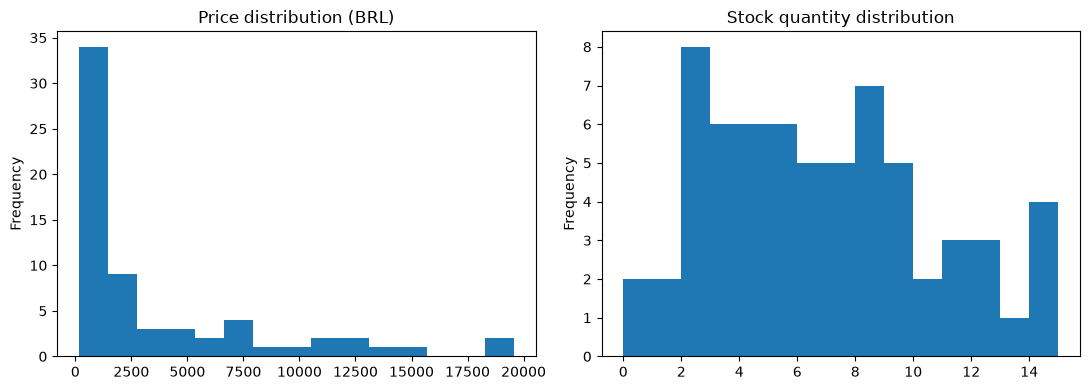

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
products["price_brl"].plot.hist(bins=15, ax=axes[0], title="Price distribution (BRL)")
products["stock_quantity"].plot.hist(bins=15, ax=axes[1], title="Stock quantity distribution")
plt.tight_layout()
plt.show()


In [5]:
products["status"].value_counts()


status
active          62
discontinued     2
coming_soon      1
Name: count, dtype: int64

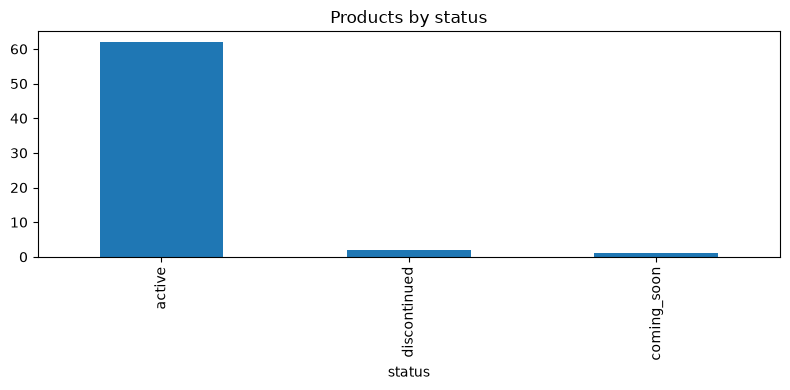

In [6]:
products["status"].value_counts().plot.bar(title="Products by status")
plt.tight_layout()
plt.show()


In [7]:
# out_of_stock_active anomaly (data-quality-report.md)
products[(products["status"] == "active") & (products["stock_quantity"] == 0)][
    ["product_id", "name", "status", "stock_quantity"]
]


,product_id,name,status,stock_quantity
15,96,Giannini GF-3D Dreadnought Sunburst,active,0


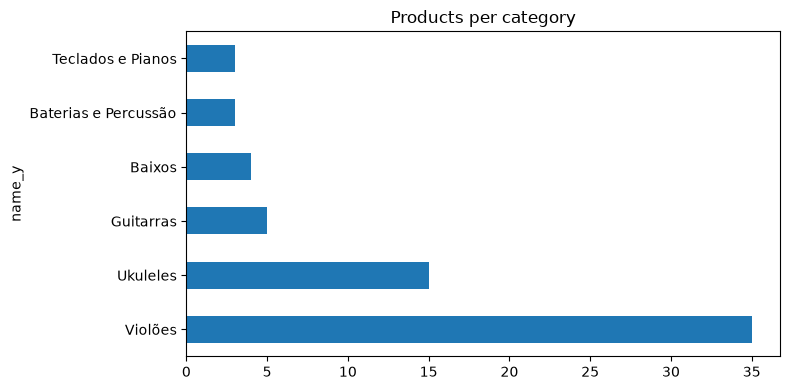

In [8]:
cat_counts = products.merge(categories, on="category_id", how="left")["name_y"].value_counts()
cat_counts.plot.barh(title="Products per category")
plt.tight_layout()
plt.show()


In [9]:
# empty_category anomaly: categories with zero products
cat_with_products = products["category_id"].unique()
categories[~categories["category_id"].isin(cat_with_products)]


,category_id,name,description
5,6,Instrumentos de Sopro (Madeiras),"Flautas, clarinetes, saxofones, oboés e outros..."
6,7,Instrumentos de Sopro (Metais),"Trompetes, trombones, tubas, trompas e outros ..."
7,8,Cordas Orquestrais,"Violinos, violas, violoncelos e contrabaixos a..."


## 3. Orders & order items

Order value, status, payment method, and a check of stored totals against the sum of
current item prices (the `order_total_mismatch` anomaly is about *historical* prices at
purchase time, so a mismatch here is expected and not itself a new finding — see
`docs/data-quality-report.md`).


In [10]:
orders["status"].value_counts()


status
delivered    7
confirmed    4
pending      4
cancelled    4
shipped      1
Name: count, dtype: int64

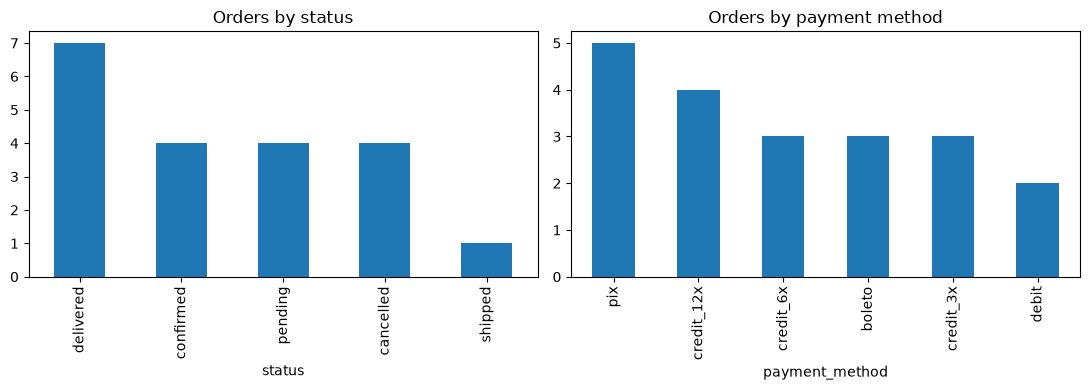

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
orders["status"].value_counts().plot.bar(ax=axes[0], title="Orders by status")
orders["payment_method"].value_counts().plot.bar(ax=axes[1], title="Orders by payment method")
plt.tight_layout()
plt.show()


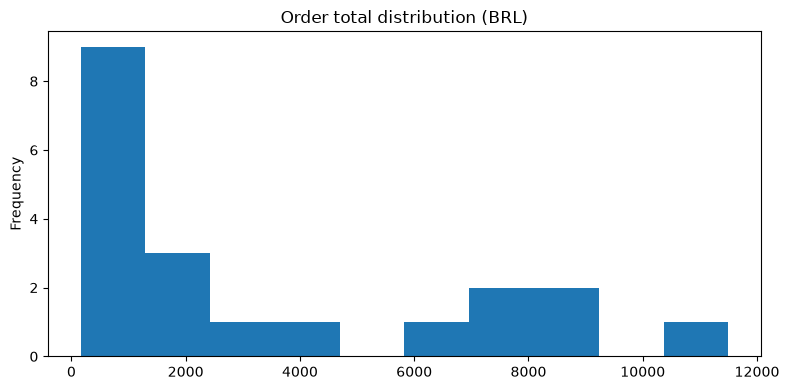

In [12]:
orders["total_brl"].plot.hist(bins=10, title="Order total distribution (BRL)")
plt.tight_layout()
plt.show()


In [13]:
items_with_price = order_items.merge(
    products[["product_id", "price_brl"]], on="product_id", how="left"
)
items_with_price["line_total"] = items_with_price["quantity"] * items_with_price["price_brl"]
order_sums = items_with_price.groupby("order_id")["line_total"].sum().rename("items_sum_current_price")
compare = orders.merge(order_sums, on="order_id", how="left")
compare["diff_current_price"] = compare["total_brl"] - compare["items_sum_current_price"]
compare[compare["diff_current_price"].abs() > 0][
    ["order_id", "total_brl", "items_sum_current_price", "diff_current_price"]
]


,order_id,total_brl,items_sum_current_price,diff_current_price
2,3,3450.0,3498.0,-48.0
19,20,1400.0,1488.0,-88.0


In [14]:
# missing_purchase_channel: orders lack a channel column entirely (§4.1 needs it for 7-day withdrawal)
"channel" in orders.columns


False

## 4. Customers

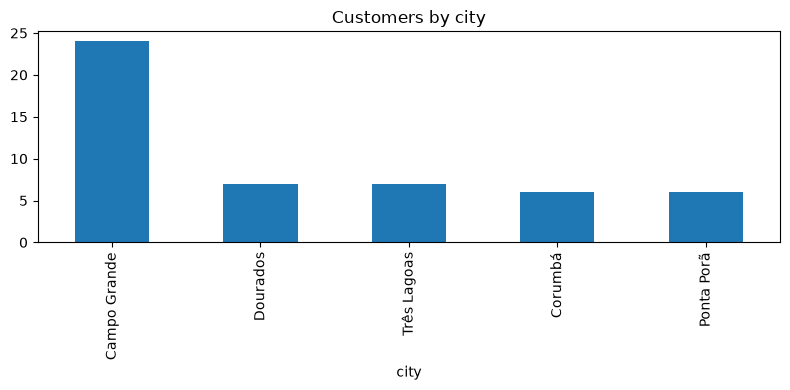

In [15]:
customers["city"].value_counts().plot.bar(title="Customers by city")
plt.tight_layout()
plt.show()


In [16]:
# shared_email anomaly
dupes = customers[customers.duplicated("email", keep=False)].sort_values("email")
dupes


,customer_id,name,phone,email,city
10,11,Bruno Carvalho Martins,(67) 98543-2109,bruno.martins@jmail.com,Três Lagoas
42,43,Bruno Martins,(67) 99456-3456,bruno.martins@jmail.com,Três Lagoas


## 5. Promotions

Active vs. duplicate promotions per product (only `is_active` promotions are real discounts;
duplicates on the same product are a known anomaly, largest discount wins per DL-002).


In [17]:
promotions["is_active"].value_counts()


is_active
0    21
1     4
Name: count, dtype: int64

In [18]:
dup_promo_products = promotions[promotions["is_active"] == 1].groupby("product_id").size()
dup_promo_products[dup_promo_products > 1]


Series([], dtype: int64)

In [19]:
active_promos = promotions[promotions["is_active"] == 1].merge(
    products[["product_id", "name", "price_brl"]], on="product_id", how="left"
)
active_promos[["product_id", "name", "price_brl", "discount_percent", "description"]]


,product_id,name,price_brl,discount_percent,description
0,127,Kalani KAL-700T Tenor Natural,359.0,10,Oferta Especial
1,121,Ohana CK-20 Concert Natural,549.0,20,Desconto Exclusivo
2,90,Crafter HT-100 Folk Aço Natural,2399.0,18,Desconto Exclusivo
3,94,Taylor 110e Dreadnought Natural,5999.0,8,Desconto Exclusivo


## 6. Cross-cutting summary

Findings surfaced above, mapped to the authoritative anomaly table in
`docs/data-quality-report.md` (DL-002):

| Finding here | `data-quality-report.md` row |
|---|---|
| Section 2: active products with 0 stock | `out_of_stock_active` |
| Section 2: discontinued / coming_soon counts | `discontinued`, `coming_soon` |
| Section 2: categories with no products | `empty_category` |
| Section 3: no `channel` column on orders | `missing_purchase_channel` |
| Section 3: stored total vs. current-price item sum | related to `order_total_mismatch` (that
  anomaly compares against *historical* item prices, not current ones; the diff shown here is
  expected for any product whose price changed since the order) |
| Section 4: duplicate customer emails | `shared_email` |
| Section 5: >1 active promotion per product | `duplicate_promotions` |
| Section 5: active promotions list | `active_promotions` |

No new anomaly beyond those already catalogued was found in this pass; this notebook adds
distributions and visual confirmation for the report's existing findings.
